In [6]:
# Provide a summary of the total gene fusion counts observed in PDO and Tumor samples, 
# including the number of unique fusions identified in each group and the specific fusions shared between them.

import pandas as pd
import os

# === FILE PATH ===
dna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"

# === LOAD FILE ===
dna_df = pd.read_csv(dna_path)
dna_df.columns = dna_df.columns.str.strip()

# === SPLIT PDO vs TUMOR ===
pdo_df = dna_df[dna_df["sample"].astype(str).str.strip().str.startswith("IPM", na=False)].copy()
tumor_df = dna_df[dna_df["sample"].astype(str).str.strip().str.startswith("TP", na=False)].copy()

# === EXTRACT FUSIONS (UNIQUE) ===
def extract_fusions(df, column):
    valid = df[column].dropna().astype(str).str.strip()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return set(fusions)

# === EXTRACT FUSIONS (INCLUDING DUPLICATES) ===
def extract_fusions_with_duplicates(df, column):
    valid = df[column].dropna().astype(str).str.strip()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return fusions

pdo_fusions = extract_fusions(pdo_df, "PutativeGeneFusion")
tumor_fusions = extract_fusions(tumor_df, "PutativeGeneFusion")

pdo_fusions_all = extract_fusions_with_duplicates(pdo_df, "PutativeGeneFusion")
tumor_fusions_all = extract_fusions_with_duplicates(tumor_df, "PutativeGeneFusion")

# === COMPARE SETS ===
pdo_only = pdo_fusions - tumor_fusions
tumor_only = tumor_fusions - pdo_fusions
shared = pdo_fusions & tumor_fusions

# === OUTPUT ===
print(f"Total gene fusions in PDO (including duplicates): {len(pdo_fusions_all)}")
print(f"Total gene fusions in Tumor (including duplicates): {len(tumor_fusions_all)}")

print(f"Total unique gene fusions in PDO: {len(pdo_fusions)}")
print(f"Total unique gene fusions in Tumor: {len(tumor_fusions)}")
print(f"PDO-only fusions: {len(pdo_only)}")
print(f"Tumor-only fusions: {len(tumor_only)}")
print(f"Shared fusions: {len(shared)}")

print("\nShared fusions:")
for fusion in sorted(shared):
    print(f" - {fusion}")

Total gene fusions in PDO (including duplicates): 634
Total gene fusions in Tumor (including duplicates): 544
Total unique gene fusions in PDO: 618
Total unique gene fusions in Tumor: 532
PDO-only fusions: 615
Tumor-only fusions: 529
Shared fusions: 3

Shared fusions:
 - AC109780.2-KNG1
 - CCDC170-ESR1
 - MIPOL1-TTC6


In [2]:
import pandas as pd
import os

# === FILE PATHS ===
dna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
rna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv"

# === LOAD FILES ===
dna_df = pd.read_csv(dna_path)
rna_df = pd.read_csv(rna_path)

# === EXTRACT FUSIONS ===
def extract_fusions(df, column):
    valid = df[column].dropna()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return fusions

# Full fusion lists
dna_fusions_all = extract_fusions(dna_df, "PutativeGeneFusion")
rna_fusions_all = extract_fusions(rna_df, "RNAFusion")

# Unique fusion sets
dna_fusions = set(dna_fusions_all)
rna_fusions = set(rna_fusions_all)

# === FIND OVERLAP ===
overlap = dna_fusions & rna_fusions

# === OUTPUT ===
print(f"Total DNA fusion count: {len(dna_fusions_all)}")
print(f"Unique DNA fusion count: {len(dna_fusions)}\n")

print(f"Total RNA fusion count: {len(rna_fusions_all)}")
print(f"Unique RNA fusion count: {len(rna_fusions)}\n")

print(f"Overlapping unique fusions across OGM and RNASeq: {len(overlap)}\n")

for fusion in sorted(overlap):
    print(f" - {fusion}")

# === SAVE OVERLAP ===
overlap_df = pd.DataFrame(sorted(overlap), columns=["OverlappingFusions"])
overlap_path = os.path.join(os.path.dirname(rna_path), "overlapping_fusions.csv")
overlap_df.to_csv(overlap_path, index=False)

print(f"\nOverlapping fusion list saved to: {overlap_path}")

Total DNA fusion count: 1178
Unique DNA fusion count: 1147

Total RNA fusion count: 411
Unique RNA fusion count: 383

Overlapping unique fusions across OGM and RNASeq: 37

 - AL109615.3-AL583836.1
 - ALCAM-AL136418.1
 - AP2B1-SKAP1
 - APBB2-PTPRR
 - ARHGEF7-ATP11A
 - ATXN2-BRAP
 - BACE2-MX1
 - CDC14A-LSAMP
 - CNOT1-GOT2
 - CTC1-STX8
 - DENND5A-SORL1
 - EDC3-PREX1
 - ESR1-ARNT2
 - ITGAV-GULP1
 - MED13-ABCA6
 - METTL16-BRCA1
 - NFE2L3-CBX3
 - NIPBL-AC034114.2
 - NUP107-OTOGL
 - OXNAD1-PLCL2
 - PCBP1-AS1-PPP1R1B
 - PITPNC1-SDK2
 - PPFIA1-ARHGAP32
 - PPFIBP2-KMT5B
 - PPP2R5E-PIGH
 - PPP3CB-SAFB
 - PRKACB-PAH
 - PVT1-PSIP1
 - RFC1-SMIM14
 - SPHK2-SEC1P
 - SPON2-FBXL5
 - TAB3-DMD
 - TPST1-AC027644.4
 - TPST1-RABGEF1
 - TUSC3-ANO1
 - UNC13B-PLEKHG6
 - UVRAG-MYO7A

Overlapping fusion list saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/overlapping_fusions.csv


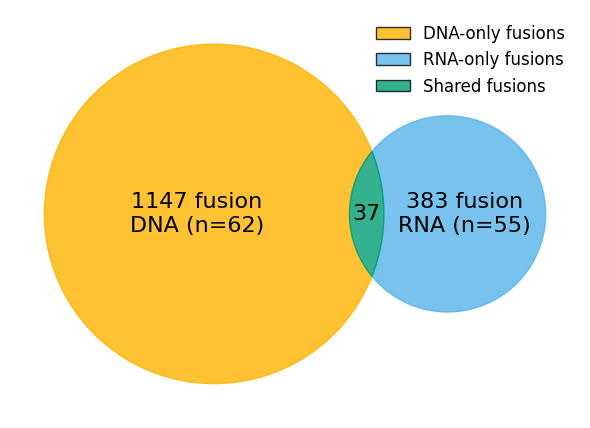

Saved Venn diagram with color legend at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/rna_dna_fusions_venn.pdf


In [3]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib.patches import Patch
import os

# Unique Fusion count
rna_fusions = 383
dna_fusions = 1147
overlap = 37

# Venn subsets (for shape only)
only_rna = rna_fusions - overlap
only_dna = dna_fusions - overlap

# Output path
output_dir = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs"
output_file = os.path.join(output_dir, "rna_dna_fusions_venn.pdf")

# Create plot
plt.figure(figsize=(6, 6))
venn = venn2(subsets=(only_dna, only_rna, overlap))  # DNA on left, RNA on right

# Set custom colors for regions
venn.get_patch_by_id('10').set_color('#FFB300')   # DNA only - amber
venn.get_patch_by_id('01').set_color('#56B4E9')   # RNA only - light blue
venn.get_patch_by_id('11').set_color('#009E73')   # Overlap - green

# Optional: transparency
venn.get_patch_by_id('10').set_alpha(0.8)
venn.get_patch_by_id('01').set_alpha(0.8)
venn.get_patch_by_id('11').set_alpha(0.8)

# Set custom labels
venn.get_label_by_id('10').set_text(f"{dna_fusions} fusion\nDNA (n=62)")
venn.get_label_by_id('01').set_text(f"{rna_fusions} fusion\nRNA (n=55)")
venn.get_label_by_id('11').set_text(f"{overlap}")

# Set font sizes
venn.get_label_by_id('10').set_fontsize(16)
venn.get_label_by_id('01').set_fontsize(16)
venn.get_label_by_id('11').set_fontsize(16)

# Remove default set labels
for label in venn.set_labels:
    if label:
        label.set_visible(False)

# Add color legend
legend_handles = [
    Patch(facecolor='#FFB300', edgecolor='black', alpha=0.8, label='DNA-only fusions'),
    Patch(facecolor='#56B4E9', edgecolor='black', alpha=0.8, label='RNA-only fusions'),
    Patch(facecolor='#009E73', edgecolor='black', alpha=0.8, label='Shared fusions')
]

plt.legend(
    handles=legend_handles,
    loc='upper right',
    frameon=False,
    fontsize=12
)

# Save and show
plt.tight_layout()
plt.savefig(output_file, dpi=300, bbox_inches='tight')

plt.show()
plt.close()

print(f"Saved Venn diagram with color legend at: {output_file}")

In [4]:
# ============================================================
# Add chromosome info to each gene after RNASeq fusion analysis
# Fully annotated fusion = both partner genes have chromosome annotation
# Not fully annotated fusion = one or both partner genes could not be mapped
# to the GTF annotation
# ============================================================

import pandas as pd
import gzip
import os

# === Input / Output ===
input_csv = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv'
gtf_file = '/ix1/genomics/refs/nf-core-rnafusion-2.1.0/references/ensembl/Homo_sapiens.GRCh38.102.gtf'

out_csv = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv'
not_fully_annotated_csv = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_not_fully_annotated.csv'

# === Load RNA fusion file ===
fusion_df = pd.read_csv(input_csv)

# === Keep only rows with a non-empty fusion call ===
valid_fusion_strings = fusion_df['RNAFusion'].notna() & ~fusion_df['RNAFusion'].isin(["", "-", "not_applicable"])
fusion_df = fusion_df.loc[valid_fusion_strings].copy()

# === Split fusion gene names using first dash only ===
fusion_df[['GeneA', 'GeneB']] = fusion_df['RNAFusion'].astype(str).str.split('-', n=1, expand=True)

# Clean spaces
fusion_df['GeneA'] = fusion_df['GeneA'].str.strip()
fusion_df['GeneB'] = fusion_df['GeneB'].str.strip()

# === Parse GTF file and build gene-to-chromosome map ===
def parse_gtf(gtf_path):
    gene_chr_map = {}
    open_func = gzip.open if gtf_path.endswith(".gz") else open

    with open_func(gtf_path, 'rt') as gtf:
        for line in gtf:
            if line.startswith('#'):
                continue

            cols = line.strip().split('\t')
            if len(cols) < 9 or cols[2] != 'gene':
                continue

            chrom = cols[0]
            attributes = cols[8]

            attrs = {}
            for attr in attributes.strip().split(';'):
                attr = attr.strip()
                if not attr:
                    continue
                key_value = attr.split(' ', 1)
                if len(key_value) == 2:
                    key, value = key_value
                    attrs[key] = value.strip('"')

            gene_name = attrs.get('gene_name')
            if gene_name and gene_name not in gene_chr_map:
                gene_chr_map[gene_name] = chrom

    return gene_chr_map

# === Load gene-to-chromosome map ===
gene_chr = parse_gtf(gtf_file)

# === Annotate chromosomes ===
fusion_df['ChrA'] = fusion_df['GeneA'].map(gene_chr)
fusion_df['ChrB'] = fusion_df['GeneB'].map(gene_chr)

# === Define annotation status ===
fusion_df['BothPartnersAnnotated'] = fusion_df['ChrA'].notna() & fusion_df['ChrB'].notna()

# === Summary counts ===
total_rows_after_filter = len(fusion_df)
total_unique_fusions = fusion_df['RNAFusion'].nunique()

total_fully_annotated_rows = fusion_df['BothPartnersAnnotated'].sum()
total_not_fully_annotated_rows = (~fusion_df['BothPartnersAnnotated']).sum()

unique_fully_annotated_fusions = fusion_df.loc[fusion_df['BothPartnersAnnotated'], 'RNAFusion'].nunique()
unique_not_fully_annotated_fusions = fusion_df.loc[~fusion_df['BothPartnersAnnotated'], 'RNAFusion'].nunique()

# Missing chromosome details
missing_chrA = fusion_df['ChrA'].isna().sum()
missing_chrB = fusion_df['ChrB'].isna().sum()
missing_either = (fusion_df['ChrA'].isna() | fusion_df['ChrB'].isna()).sum()

# === Save outputs ===
fusion_df.to_csv(out_csv, index=False)

# === Print summary ===
print("==========================================")
print("RNA Fusion chromosome annotation summary")
print("==========================================")
print(f"Total fusion rows after removing empty RNAFusion entries         : {total_rows_after_filter}")
print(f"Total unique RNA fusions                                         : {total_unique_fusions}")
print()
print(f"Total fully annotated fusion rows                                : {total_fully_annotated_rows}")
print(f"Total not fully annotated fusion rows                            : {total_not_fully_annotated_rows}")
print(f"Unique fully annotated RNA fusions                               : {unique_fully_annotated_fusions}")
print(f"Unique not fully annotated RNA fusions                           : {unique_not_fully_annotated_fusions}")
print()
print(f"Rows missing ChrA                                                : {missing_chrA}")
print(f"Rows missing ChrB                                                : {missing_chrB}")
print(f"Rows missing either ChrA or ChrB                                 : {missing_either}")
print()
print(f"Annotated output saved to: {out_csv}")
print()

# === Preview ===
print("Preview:")
print(fusion_df[['RNAFusion', 'GeneA', 'ChrA', 'GeneB', 'ChrB', 'BothPartnersAnnotated']].head(10))

RNA Fusion chromosome annotation summary
Total fusion rows after removing empty RNAFusion entries         : 411
Total unique RNA fusions                                         : 383

Total fully annotated fusion rows                                : 408
Total not fully annotated fusion rows                            : 3
Unique fully annotated RNA fusions                               : 380
Unique not fully annotated RNA fusions                           : 3

Rows missing ChrA                                                : 0
Rows missing ChrB                                                : 3
Rows missing either ChrA or ChrB                                 : 3

Annotated output saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv

Preview:
               RNAFusion       GeneA ChrA       GeneB ChrB  \
0             EDC3-PREX1        EDC3   15       PREX1   20   
1             PREX1-EDC3       PREX1   20        EDC3   15   
2           CTTN-BDNF-AS        